# Example: RMDC26_001532 — a blind Roman event with a double peak

The fifth blind example on simulated Roman data. The event has two peaks of similar height, eleven hours apart:
the first is the peak of the host star, the second comes from a small central caustic. The map shows the
textbook picture of a central-caustic close/wide degeneracy: two tilted valleys, mirror images of each other,
with the close solution preferred.

As for `example_rmdc26_001279`, the angle-screen guided starts do not find the solution and **caustic-crossing
starts** do; unlike there, the valleys are broad enough for the coarse map to find them.

**The data.** RMDC26_001532 is an event of the *Experienced tier* of the Roman Microlensing Data Challenge 2026
(RGES-PIT; public domain, CC0, [huggingface.co/datasets/RGES-PIT/Experienced](https://huggingface.co/datasets/RGES-PIT/Experienced)),
simulated with GULLS (Penny et al. 2019). The true parameters are not published, so this is a **blind** analysis.
The line of sight is heavily reddened (12.7, 5.1 and 1.7 mag of extinction in F087, F146 and F213); as for
RMDC26_001576, the F087 points are pure noise and stay in the fit with their own source and blend flux.

**Runtime.** On a 14-core Intel Core i5-13500 (20 threads): guided fits 75 minutes (most of it in the
caustic-crossing starts), coarse map 30 minutes, zooms 20 + 14 + 4 + 4 minutes, polish a few minutes. Everything is
stored in `data/`, so the notebook runs in a few seconds by default; `RECOMPUTE = True` computes it all again (about
2.5 hours).

## 0. Setup

In [1]:
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import figures, caustics, model

RECOMPUTE = False              # True: compute all maps and fits again (about 2.5 hours on a 20-thread desktop)
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/rmdc1532_photometry.csv`: all points (none saturated), with `set` (filter), `t` (BJD − 2460000) and `flux`,
`flux_err` in micro-Jansky as provided. Magnitudes below are AB, 23.9 − 2.5 log₁₀(flux / µJy).

In [2]:
SETS = ["F087", "F146", "F213"]
rows = np.genfromtxt("data/rmdc1532_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
sel = lambda r, n: (r["t"][r["set"] == n], r["flux"][r["set"] == n], r["flux_err"][r["set"] == n])
data_all = lenscape.Data.from_sets({n: sel(rows, n) for n in SETS})
mag = lambda f: 23.9 - 2.5 * np.log10(f)                # AB magnitude of a flux in micro-Jansky
for n in SETS:
    t, f, e = sel(rows, n)
    print(f"{n}: {len(t)} points, median flux {np.median(f):9.4f} uJy, median error {np.median(e):.4f} uJy")

F087: 1501 points, median flux    0.0022 uJy, median error 0.2757 uJy
F146: 46488 points, median flux    1.6921 uJy, median error 0.1805 uJy
F213: 1499 points, median flux  107.8672 uJy, median error 0.9459 uJy


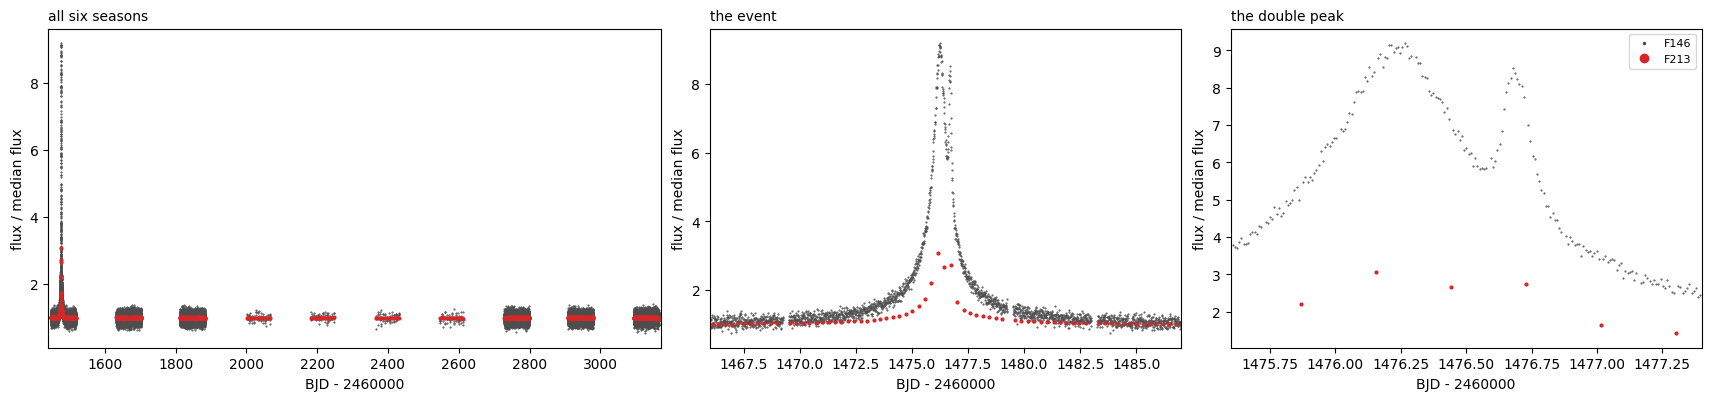

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1, 1]), constrained_layout=True)
for ax, (a, b) in zip(axs, ((1440, 3170), (1466, 1487), (1475.6, 1477.4))):
    for n, c in (("F146", "0.3"), ("F213", "C3")):
        k = data_all.names.index(n)
        m = (data_all.idx == k) & (data_all.t > a) & (data_all.t < b)
        ax.plot(data_all.t[m], data_all.f[m] / np.median(data_all.f[data_all.idx == k]), ".", ms=1 if n == "F146" else 4,
                color=c, label=n, rasterized=True)
    ax.set_xlim(a, b); ax.set_xlabel("BJD - 2460000"); ax.set_ylabel("flux / median flux")
axs[0].set_title("all six seasons", loc="left", fontsize=10)
axs[1].set_title("the event", loc="left", fontsize=10)
axs[2].set_title("the double peak", loc="left", fontsize=10); axs[2].legend(fontsize=8, markerscale=3)

The event peaks at BJD′ = 1476.25 (BJD′ = BJD − 2460000), in the first season. F146 brightens by a factor of 9,
F213 by 3 (other stars contribute more of its baseline). The peak is double: a rounded maximum, a dip of a third,
and eleven hours later a second, sharper peak almost as high.

## 2. Reducing the data for the maps

The same reduction as in the other examples: the first season only (BJD′ 1447–1519), F146 at full cadence over the
double peak (BJD′ 1475.6–1477.4), in 1-hour bins within one Einstein timescale of the single-lens screen fit
(*t*₀ = 1476.28, *t*ₑ = 5.51 d) and 3-hour bins elsewhere; F087 and F213 unbinned.

In [4]:
SEASON = (1447.0, 1519.0)
ANOM = (1475.6, 1477.4)
T0_BIN, TE_BIN = 1476.28, 5.51
def reduce(rows):
    # season only; F146: full cadence in ANOM, 1-h bins within TE_BIN of T0_BIN, 3-h bins elsewhere
    out = {}
    for n in SETS:
        t, f, e = sel(rows, n)
        m = (t >= SEASON[0]) & (t <= SEASON[1])
        t, f, e = t[m], f[m], e[m]
        if n != "F146":
            out[n] = (t, f, e); continue
        full = (t >= ANOM[0]) & (t <= ANOM[1])
        inner = np.abs(t - T0_BIN) < TE_BIN
        key = np.floor((t - SEASON[0]) / np.where(inner, 1 / 24, 3 / 24)).astype(int) * 2 + inner
        b = ~full
        u, inv = np.unique(key[b], return_inverse=True)
        w = 1 / e[b] ** 2
        W = np.bincount(inv, w)
        T, F, E = (np.r_[t[full], np.bincount(inv, w * t[b]) / W], np.r_[f[full], np.bincount(inv, w * f[b]) / W],
                   np.r_[e[full], W ** -0.5])
        o = np.argsort(T)
        out[n] = (T[o], F[o], E[o])
    return lenscape.Data.from_sets(out)

data = reduce(rows)
season = data_all.window(*SEASON)
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
print(f"all {len(data_all)} points, season {len(season)}, binned {len(data)}:",
      {n: len(s) for n, s in zip(data.names, data.slices)})

all 49488 points, season 8181, binned 1366: {'F087': 240, 'F146': 885, 'F213': 241}


## 3. Finding the solution: caustic-crossing starts

The single lens (double peak masked) gives χ² = 21 400 on the 1366 binned points. The angle screen of the earlier
examples (the single-lens trajectory at 360 angles for each *s*, *q*, ρ, the 24 best fitted in full) ends no
better than χ² = 4112: a double peak whose second half is sharp needs the trajectory placed within a few source radii
of a cusp, which a coarse angle grid rarely does.

As for RMDC26_001279, `lenscape.fit.fit_point` is started from **caustic crossings** (Cassan 2008) instead. The trial
pairs are the sharp second peak (BJD′ 1476.62–1476.74), both peaks (1476.15–1476.72) and the first peak
(1476.20–1476.32). On a grid of log *s* = −0.6 … 0.6 (step 0.1) and log *q* = −4 … 0 (step 0.5), the 8 best distinct
results are fitted in all seven parameters, plus the offset partners of the 4 best.

In [5]:
first_file = "data/rmdc1532_first_fits.json"
if RECOMPUTE or not os.path.exists(first_file):
    log("computing the guided fits (caustic-crossing starts)")
    from multiprocessing import get_context
    from scipy.optimize import minimize
    m = data.select(~((data.t >= ANOM[0]) & (data.t <= ANOM[1])))
    def c2_single(x):
        A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]) + 1e-3, 10 ** min(x[3], -0.5), m.t, 0.0)
        return model.chi2_profiled(A, m.f, m.w, m.idx, m.nsets)
    r = min((minimize(c2_single, [1476.28, u0, tE, -2.5], method="Nelder-Mead", options=dict(maxfev=4000, adaptive=True))
             for u0 in (0.02, 0.05, 0.1) for tE in (5.0, 10.0, 20.0)), key=lambda r: r.fun)
    sl = dict(t0=float(r.x[0]), u0=abs(float(r.x[1])), tE=abs(float(r.x[2])) + 1e-3)
    CROSS = [(1476.62, 1476.74), (1476.15, 1476.72), (1476.20, 1476.32)]
    CFG = dict(lenscape.config.DEFAULT, seed=dict(t0=sl["t0"], u0=max(sl["u0"], 0.005), tE=sl["tE"], logrho=-3.0),
               caustic_crossings=CROSS, n_caustic=6, caustic_samples=32, n_screen=4)
    grid = lenscape.make_backend(lenscape.config.GRID_BACKEND)
    def point(a):
        try:
            c, x = lenscape.fit.fit_point(a[0], a[1], data, CFG)
            return float(c), [float(x[0]), float(x[1]), float(x[2]), a[0], a[1], float(x[3]), float(x[4])]
        except Exception:
            return np.inf, None
    def full_fit(p):
        c, p = lenscape.fit_full(data, np.array(p), grid, rounds=2, maxfev=3000)
        c, p = lenscape.fit_full(data, p, be, rounds=2, maxfev=3000)
        return float(c), [float(v) for v in p]
    pts = [(round(a, 3), round(b, 3)) for a in np.arange(-0.6, 0.601, 0.1) for b in np.arange(-4.0, 0.01, 0.5)]
    with get_context("fork").Pool() as pool:               # about 70 minutes on 20 threads
        res = sorted([r for r in pool.map(point, pts) if r[1] is not None], key=lambda r: r[0])
        starts = []
        for c, p in res:
            if all(abs(p[3] - q[3]) > 0.15 or abs(p[4] - q[4]) > 0.6 for _, q in starts):
                starts.append((c, p))
        fits = pool.map(full_fit, [p for _, p in starts[:8]])
        fits += pool.map(full_fit, [lenscape.fit.offset_partner(np.array(p)).tolist() for _, p in sorted(fits)[:4]])
    json.dump(dict(single_lens=sl, fits=sorted(fits), caustic_fits=dict(crossings=CROSS, grid=res, fits=sorted(fits))),
              open(first_file, "w"), indent=1)
first = json.load(open(first_file))
print(f"crossing pairs tried: {first['caustic_fits']['crossings']}")
print(f"{'chi2':>9s} {'log s':>8s} {'log q':>7s} {'alpha':>6s} {'u0':>8s} {'tE':>7s} {'log rho':>7s}")
shown = []
for c, p in sorted(first["caustic_fits"]["fits"]):
    if all(abs(p[3] - q[3]) > 0.003 or abs(p[4] - q[4]) > 0.03 for _, q in shown):
        shown.append((c, p))
        print(f"{c:9.2f} {p[3]:+8.4f} {p[4]:+7.3f} {p[5] % (2 * np.pi):6.3f} {p[1]:+8.5f} {p[2]:7.3f} {p[6]:+7.3f}")
best_first = np.array(first["fits"][0][1])

crossing pairs tried: [[1476.62, 1476.74], [1476.15, 1476.72], [1476.2, 1476.32]]
     chi2    log s   log q  alpha       u0      tE log rho
  1393.06  -0.1131  -2.412  2.653 +0.02565   8.796  -2.466
  1409.25  +0.1387  -2.428  2.648 +0.02338   9.350  -2.500
  4070.54  +0.3675  -1.009  4.286 +0.13996  15.006  -2.131
  4222.17  -0.3368  -0.989  1.948 +0.01502  13.690  -2.097
  4428.21  +0.3831  -1.481  1.993 -0.05353  42.765  -2.601
  4510.95  -0.4274  -1.641  4.332 -0.00253  79.678  -2.889
  4527.08  +0.4033  -2.000  4.296 +0.01797 152.320  -3.163
  4602.27  -0.0866  -1.397  4.156 -0.05190   5.777  -1.732
  5752.44  -0.2562  -2.599  2.421 +0.00125 200.651  -3.061


Two fits stand out, a **close** one (log *s* = −0.113, χ² = 1393.1 for 1366 binned points) and a **wide** one
(log *s* = +0.139, 16 higher), both with log *q* ≈ −2.42. Everything else ends more than 2600 higher.

In [6]:
wide_first = np.array([p for c, p in first["fits"] if p[3] > 0][0])
check = {"close": best_first, "wide": wide_first}
c = {k: [model.chi2(be, p, d) for d in (data, season, data_all)] for k, p in check.items()}
print(f"{'':7s} {'binned':>10s} {'season':>10s} {'all':>10s}   (Delta chi2 to the close fit)")
for k, v in c.items():
    print(f"{k:7s} " + " ".join(f"{a - b:10.2f}" for a, b in zip(v, c["close"])))
print(f"close fit: chi2 = {c['close'][0]:.1f} (binned, N = {len(data)}), {c['close'][1]:.1f} (season, N = {len(season)}), "
      f"{c['close'][2]:.1f} (all, N = {len(data_all)})")

            binned     season        all   (Delta chi2 to the close fit)
close         0.00       0.00       0.00
wide         16.19      16.18      20.47
close fit: chi2 = 1393.1 (binned, N = 1366), 8319.3 (season, N = 8181), 49304.9 (all, N = 49488)


The binned data reproduce the Δχ² of the unbinned season and of all six seasons.

## 4. The coarse map

The same lattice as before: −1 ≤ log *s* ≤ 1 in steps of 0.04, −5 ≤ log *q* ≤ 0 in steps of 0.1, 51 × 51
points, no refinement more than 500 above the minimum. **Runtime: 30 minutes.**

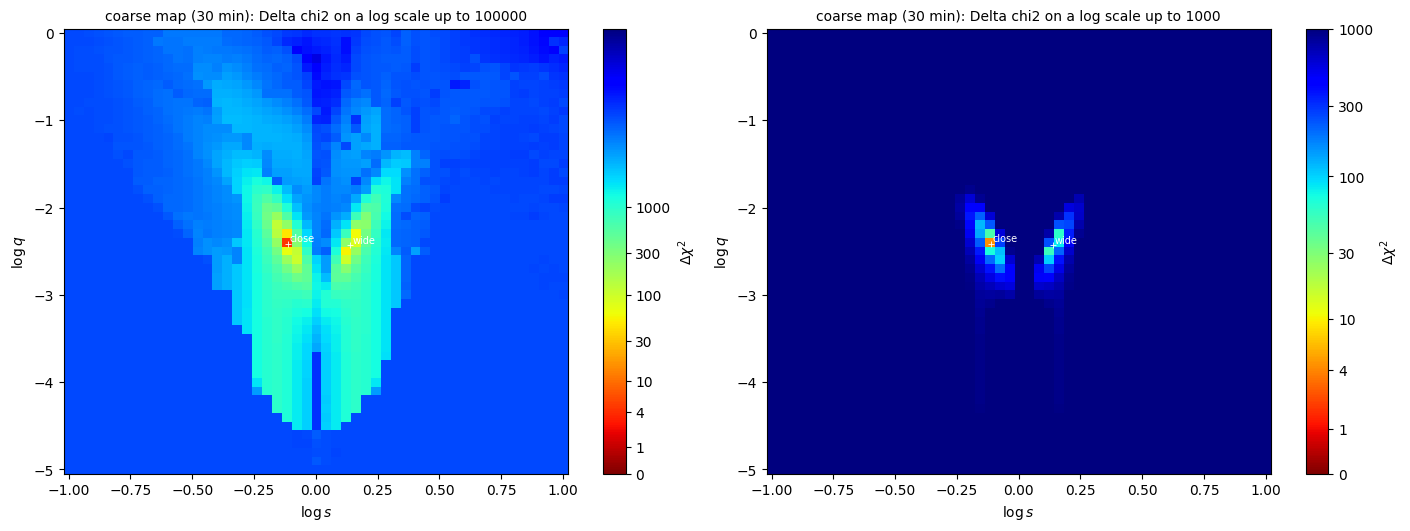

In [7]:
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def run_or_load(name, compute):
    # data/rmdc1532_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/rmdc1532_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

logs1 = np.round(np.arange(-1.0, 1.0001, 0.04), 4)
logq1 = np.round(np.arange(-5.0, 0.0001, 0.1), 4)
map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best_first, bin_wings=False, dchi2_cut=5.0,
                                                  log=log))
ref0 = first["fits"][0][0]
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
for ax, vmax in zip(axs, (100000, 1000)):
    figures.plot_map(map1, ax=ax, vmax=vmax, chi2_ref=ref0, marks={"close": best_first[3:5], "wide": wide_first[3:5]})
    ax.set_title(f"coarse map ({map1['wall'] / 60:.0f} min): Delta chi2 on a log scale up to {vmax}", fontsize=10)

Left, on a scale up to 100 000: a V with its tip at log *q* ≈ −4.5, as for the other central-caustic events. Inside it
two bright arms rise from log *q* ≈ −4.5 at log *s* ≈ ±0.05 to log *q* ≈ −2 at log *s* ≈ ±0.25. Right, on a scale
up to 1000: only the upper parts of the arms remain, two tilted valleys, mirror images of each other in log *s*.
Along each, the central caustic keeps the size the second peak needs: in the close valley a smaller *s* must be
paired with a larger *q*, in the wide valley a larger *s*. The best lattice point (log *s* = −0.12,
log *q* = −2.4) is already within 4 of the minimum; the wide valley's best point is 54 above it.

## 5. Zooming into the two valleys

`lenscape.maps.densify` refines boxes aligned with the coarse lattice, first at 4× (0.01 × 0.025) over each valley,
then at 64× × 16× (0.000625 × 0.00625) around each minimum.

In [8]:
step = lambda lo, hi, x0, st: np.round(x0 + st * np.arange(int(np.ceil((lo - x0) / st - 1e-9)),
                                                           int(np.floor((hi - x0) / st + 1e-9)) + 1), 6)
dens = lambda prev, s, q, fs, fq: lenscape.maps.densify(prev, data, step(*s, -1.0, 0.04 / fs), step(*q, -5.0, 0.1 / fq),
                                                         best=best_first, bin_wings=False, log=log)
mapc4 = run_or_load("close_4x", lambda: dens([map1], (-0.24, -0.04), (-3.0, -1.8), 4, 4))
mapw4 = run_or_load("wide_4x", lambda: dens([map1], (0.04, 0.28), (-3.0, -1.8), 4, 4))
mapc64 = run_or_load("close_64x", lambda: dens([mapc4, map1], (-0.126, -0.100), (-2.50, -2.34), 64, 16))
mapw64 = run_or_load("wide_64x", lambda: dens([mapw4, map1], (0.126, 0.152), (-2.51, -2.35), 64, 16))
MAPS = [("coarse", map1), ("close 4x", mapc4), ("wide 4x", mapw4), ("close 64x", mapc64), ("wide 64x", mapw64)]
ref = min(np.nanmin(m["chi2"]) for _, m in MAPS)
for name, m in MAPS:
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"{name:10s}: {m['chi2'].shape[0]:2d} x {m['chi2'].shape[1]:2d} points, {m['wall'] / 60:4.1f} min, lowest point "
          f"{m['chi2'][i, j] - ref:7.2f} at log s = {m['logs'][i]:+.6f}, log q = {m['logq'][j]:.5f}")

coarse    : 51 x 51 points, 29.6 min, lowest point    4.05 at log s = -0.120000, log q = -2.40000
close 4x  : 21 x 49 points, 20.3 min, lowest point    0.50 at log s = -0.110000, log q = -2.42500
wide 4x   : 25 x 49 points, 14.2 min, lowest point   16.08 at log s = +0.140000, log q = -2.42500
close 64x : 42 x 26 points,  4.0 min, lowest point    0.00 at log s = -0.111875, log q = -2.41875
wide 64x  : 42 x 26 points,  3.7 min, lowest point   15.70 at log s = +0.138125, log q = -2.43125


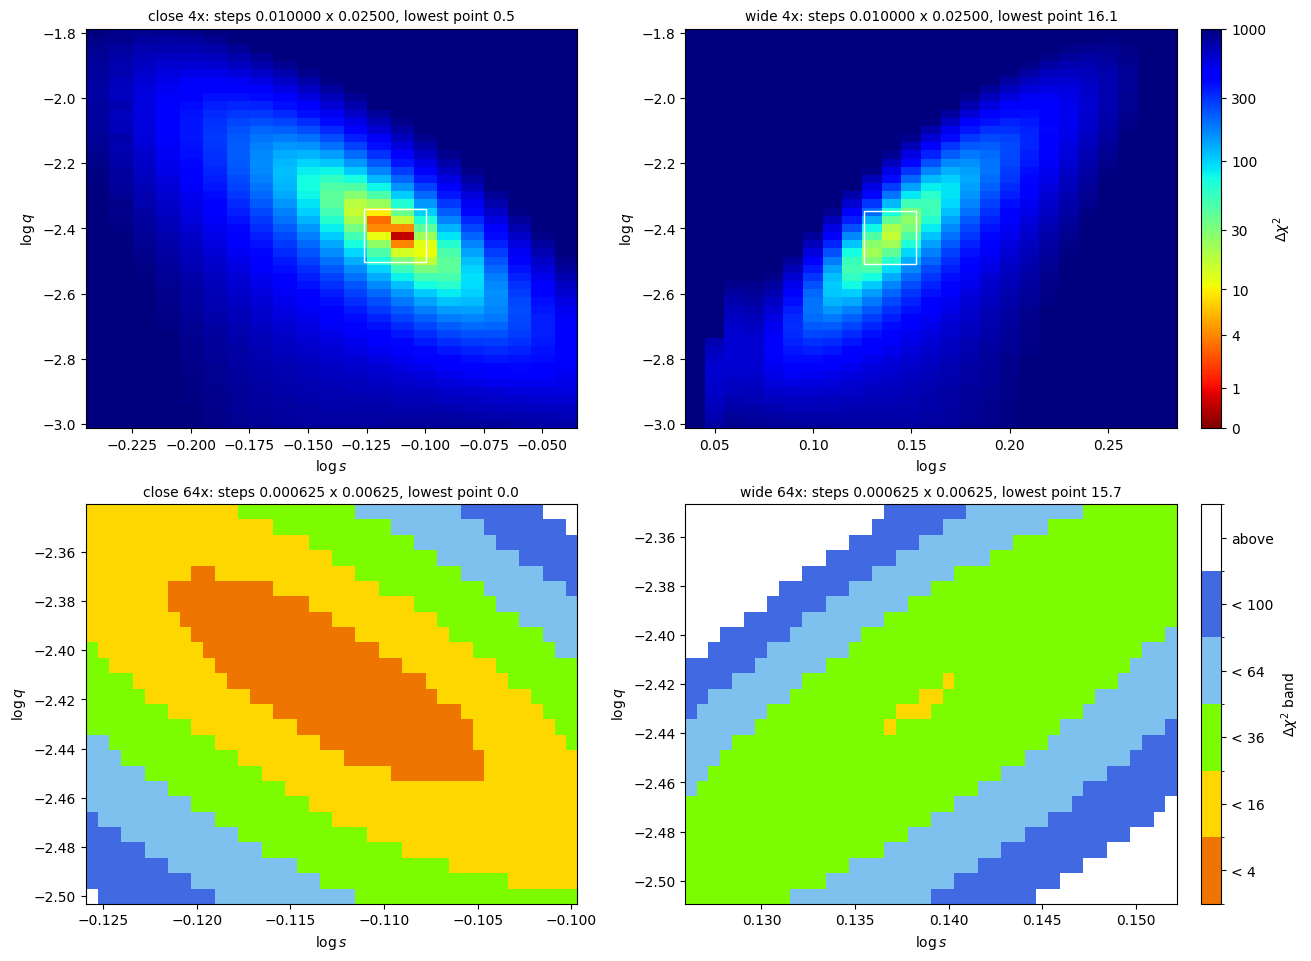

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9.5), constrained_layout=True)
for ax, (name, m) in zip(axs.ravel(), MAPS[1:]):
    if name.endswith(" 4x"):
        figures.plot_map(m, ax=ax, vmax=1000, chi2_ref=ref, colorbar=(ax is axs[0, 1]))
        z = MAPS[3 if "close" in name else 4][1]
        hs, hq = (z["logs"][1] - z["logs"][0]) / 2, (z["logq"][1] - z["logq"][0]) / 2
        ax.add_patch(plt.Rectangle((z["logs"][0] - hs, z["logq"][0] - hq), z["logs"][-1] - z["logs"][0] + 2 * hs,
                                   z["logq"][-1] - z["logq"][0] + 2 * hq, fill=False, ec="w", lw=1))
    else:
        figures.plot_map(m, bands=(4, 16, 36, 64, 100), ax=ax, chi2_ref=ref, colorbar=(ax is axs[1, 1]))
    ax.set_title(f"{name}: steps {m['logs'][1] - m['logs'][0]:.6f} x {m['logq'][1] - m['logq'][0]:.5f}, "
                 f"lowest point {np.nanmin(m['chi2']) - ref:.1f}", fontsize=10)

Top: the 4× boxes on a log scale up to 1000, with the 64× boxes outlined; bottom: the 64× boxes with Δχ² bands 4,
16, 36, 64, 100. Each valley is a single, elongated, tilted ellipse. The close minimum, at log *s* = −0.1119 and
log *q* = −2.419, is the global one; the wide minimum, at log *s* = +0.1381 and log *q* = −2.431, is 16 above it. In
the close valley Δχ² < 4 spans about 0.016 dex in log *s* and 0.08 dex in log *q* along the tilt, several times wider
than for RMDC26_001279. The 64× boxes were more than needed here; the 4× boxes already show the shape.

## 6. The best fit

In [10]:
best_file = "data/rmdc1532_best.json"
if RECOMPUTE or not os.path.exists(best_file):
    log("polishing the two solutions")
    out = {}
    for name, m, extra in (("close", mapc64, best_first), ("wide", mapw64, wide_first)):
        i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
        x = m["pars"][i, j]
        starts = [np.array([x[0], x[1], x[2], m["logs"][i], m["logq"][j], x[3], x[4]]), extra]
        c_b, p_b = min((lenscape.fit_full(data, p, be, rounds=3, maxfev=6000) for p in starts), key=lambda r: r[0])
        c_s, p_s = lenscape.fit_full(season, p_b, be, rounds=2, maxfev=4000)
        out[name] = dict(p_binned=list(p_b), p_season=list(p_s))
    json.dump(dict(p_binned=out["close"]["p_binned"], p_season=out["close"]["p_season"], wide=out["wide"]),
              open(best_file, "w"), indent=1)
bj = json.load(open(best_file))
best, wide = np.array(bj["p_season"]), np.array(bj["wide"]["p_season"])
for name, p in (("close", best), ("wide", wide)):
    print(f"{name}: t0 = {p[0]:.4f}, u0 = {p[1]:+.5f}, tE = {p[2]:.3f} d, s = {10 ** p[3]:.5f}, q = {10 ** p[4]:.4e}, "
          f"alpha = {p[5] % (2 * np.pi):.4f}, rho = {10 ** p[6]:.3e}")
    print(f"       chi2 season {model.chi2(be, p, season):.1f} (N = {len(season)}), all {model.chi2(be, p, data_all):.1f} "
          f"(N = {len(data_all)})")
r = model.residuals(be, best, season)
for k, n in enumerate(season.names):
    print(f"  close, {n}: chi2 / N = {np.sum(r[season.idx == k] ** 2):.1f} / {np.sum(season.idx == k)}")
fs, fb = model.fluxes(model.magnification(be, best, season), season)
for k, n in enumerate(season.names):
    print(f"  {n}: source flux {fs[k]:8.4f} uJy, blend {fb[k]:8.4f} uJy" +
          (f" ({mag(fs[k]):.2f} and {mag(fb[k]):.2f} AB)" if fs[k] > 0 and fb[k] > 0 else ""))

close: t0 = 1476.2776, u0 = +0.02565, tE = 8.796 d, s = 0.77067, q = 3.8747e-03, alpha = 2.6531, rho = 3.421e-03
       chi2 season 8319.3 (N = 8181), all 49304.9 (N = 49488)
wide: t0 = 1476.2949, u0 = +0.02338, tE = 9.350 d, s = 1.37621, q = 3.7292e-03, alpha = 2.6480, rho = 3.161e-03
       chi2 season 8335.5 (N = 8181), all 49325.3 (N = 49488)


  close, F087: chi2 / N = 249.1 / 240
  close, F146: chi2 / N = 7764.7 / 7700
  close, F213: chi2 / N = 305.5 / 241
  F087: source flux  -0.0011 uJy, blend  -0.0152 uJy
  F146: source flux   0.3855 uJy, blend   1.2935 uJy (24.93 and 23.62 AB)
  F213: source flux   6.7486 uJy, blend 101.0814 uJy (21.83 and 18.89 AB)


| parameter | close (best) | wide |
|---|---|---|
| *t*₀ (BJD′) | 1476.278 | 1476.295 |
| *u*₀ | 0.0257 | 0.0234 |
| *t*ₑ | 8.80 d | 9.35 d |
| *s* | 0.7707 | 1.3762 |
| *q* | 3.87 × 10⁻³ | 3.73 × 10⁻³ |
| α | 2.653 rad | 2.648 rad |
| ρ | 3.42 × 10⁻³ | 3.16 × 10⁻³ |
| χ² (all 49 488 points) | 49 304.9 | +20.5 |

The wide solution has *s* ≈ 1/0.73, close to the inverse of the close one, and nearly the same *q*. The close one is
preferred by Δχ² = 16 on the season and 20 on all six seasons.

χ²/N is 1.01 in F146 and 1.04 in F087, but 1.27 in F213 (305 for 241 points). The excess is not in the double
peak: it is spread over the whole first season, where the F213 residuals drift slowly by about half a sigma from week
to week; in the other seasons F213 has χ²/N ≈ 1, and F146, with 30 times more points, shows no such drift. It may be
slow variability of a blended star in F213; it is not investigated further here.

## 7. The light curve

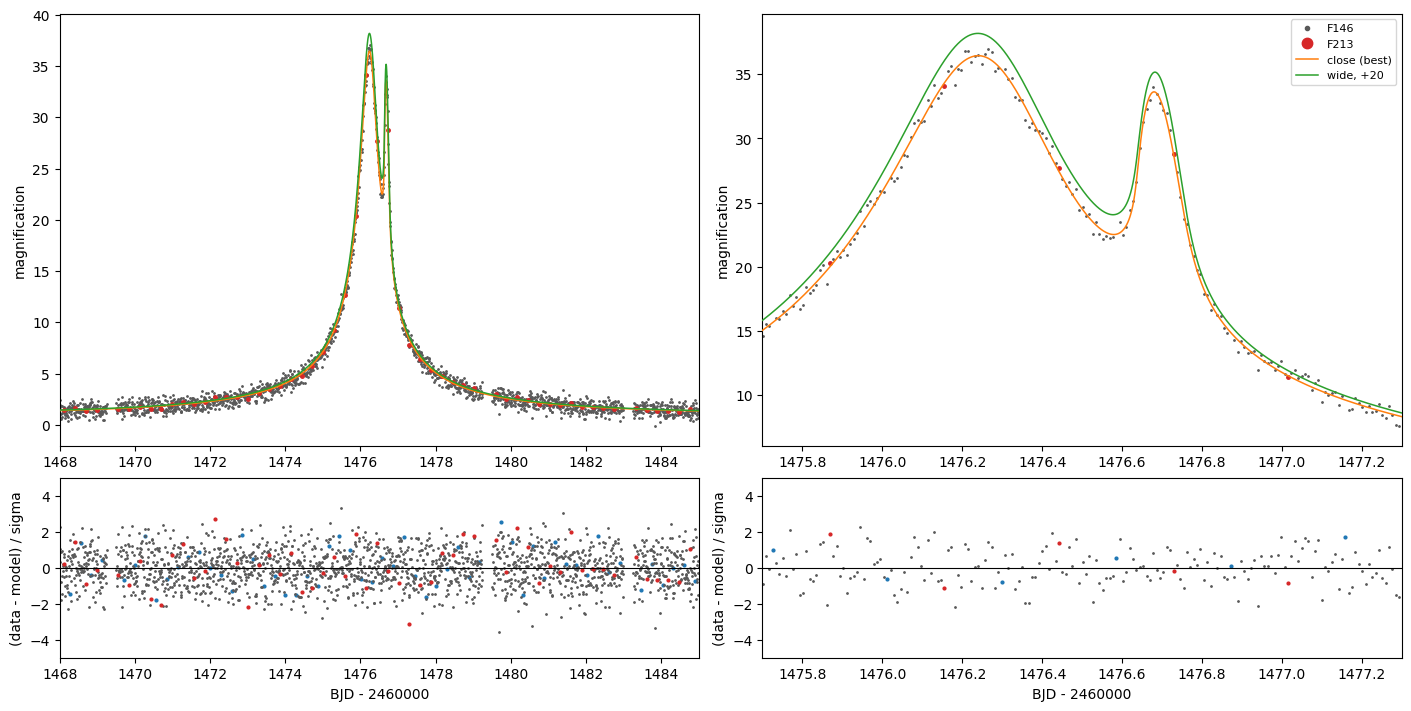

In [11]:
def plot_lc(sols, d=season, window=(1468, 1485), zoom=(1475.7, 1477.3)):
    # F146 and F213 as magnifications implied by each point (for the first solution); models; residuals of the first
    p = sols[0][1]
    fs, fb = model.fluxes(model.magnification(be, p, d), d)
    fig = plt.figure(figsize=(14, 7), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[2.4, 1])
    res = model.residuals(be, p, d)
    for col, (a, b) in enumerate((window, zoom)):
        ax, axr = fig.add_subplot(gs[0, col]), fig.add_subplot(gs[1, col])
        for k, (n, c) in enumerate(zip(d.names, ["C0", "0.35", "C3"])):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            if n != "F087":
                ax.plot(d.t[m], (d.f[m] - fb[k]) / fs[k], ".", ms=2 if n == "F146" else 5, color=c, label=n, zorder=2)
            axr.plot(d.t[m], res[m], ".", ms=2 if n == "F146" else 4, color=c)
        tt = np.linspace(a, b, 6000)
        for (lab, q), c in zip(sols, ("C1", "C2")):
            ax.plot(tt, be.lc(model.clamp(q)[0], tt), color=c, lw=1.1, label=lab, zorder=3)
        ax.set_xlim(a, b); ax.set_ylabel("magnification")
        axr.axhline(0, color="k", lw=0.8); axr.set_xlim(a, b); axr.set_ylim(-5, 5)
        axr.set_ylabel("(data - model) / sigma"); axr.set_xlabel("BJD - 2460000")
    ax.legend(fontsize=8, markerscale=3)
    return fig

plot_lc([("close (best)", best), ("wide, +20", wide)]);

The light curve is drawn as magnification (the flux of each point with the fitted blend removed and divided by the
source flux), so F146 and F213 fall on one curve; F087, all noise, is shown only in the residuals. The model follows
the double peak: the first maximum at magnification 37 (BJD′ 1476.24), the dip to 22 at 1476.58, and the second
maximum at 34 (1476.68), which rises and falls more steeply than the first. The residuals are flat. The wide solution
(green) is almost indistinguishable at this scale.

## 8. The caustic and the source trajectory

caustic curves (close): 3


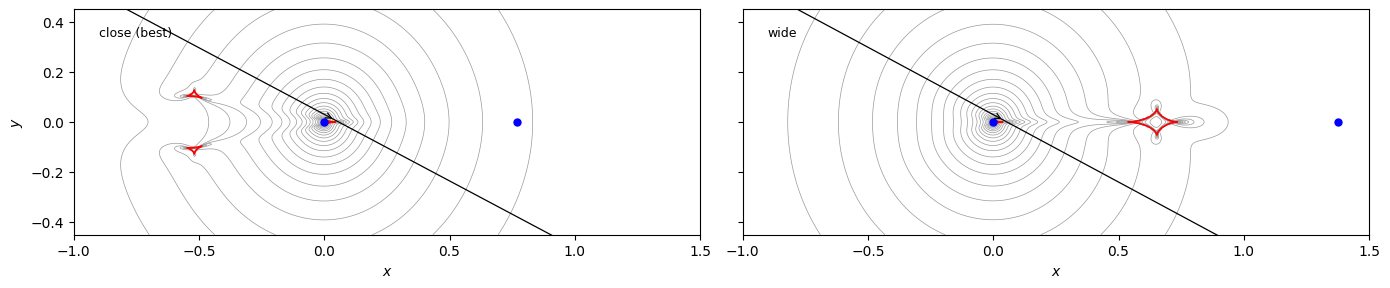

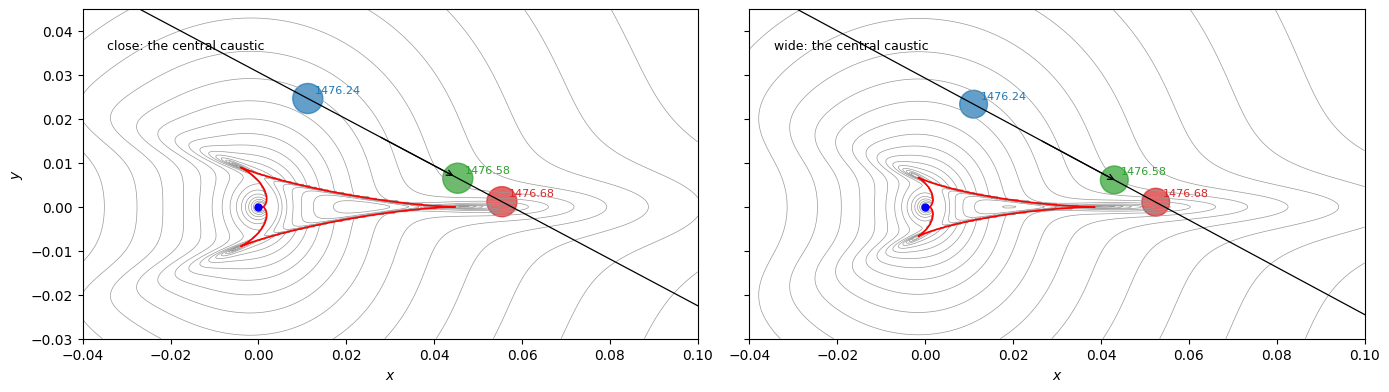

In [12]:
fig = figures.plot_geometry([best, wide], labels=["close (best)", "wide"], ncols=2, figsize=(14, 4.2),
                            extent=(-1.0, 1.5, -0.45, 0.45))
fig = figures.plot_geometry([best, wide], labels=["close: the central caustic", "wide: the central caustic"], ncols=2,
                            figsize=(14, 4.6), extent=(-0.04, 0.10, -0.03, 0.045), t_arrow=1476.4)
for ax, p in zip(fig.axes, (best, wide)):
    x0 = caustics.lens_positions(10 ** p[3], 10 ** p[4])[0]
    for t, c in ((1476.24, "C0"), (1476.58, "C2"), (1476.68, "C3")):
        z = caustics.trajectory(p, [t])[0]
        ax.add_patch(plt.Circle((z.real - x0, z.imag), 10 ** p[6], color=c, alpha=0.7))
        ax.annotate(f"{t:.2f}", (z.real - x0, z.imag), xytext=(5, 4), textcoords="offset points", fontsize=8, color=c)
print("caustic curves (close):", len(caustics.caustics(10 ** best[3], 10 ** best[4], 500)))

Top: the whole system. In the close solution the planet is at *x* = 0.77 Einstein radii from the host (origin), inside
the Einstein ring, and its two small triangular planetary caustics lie on the far side of the host, at *x* ≈ −0.52;
in the wide solution the planet is at *x* = 1.38 and its single planetary caustic lies between host and planet.
The source passes neither. Bottom: the central caustic, a small arrowhead 0.05 Einstein radii long and 0.018 wide.
The source (coloured discs: its size at the two maxima and the dip) passes 0.026 Einstein radii above the host,
which makes the first maximum, the host's own peak. It then moves down and to the right, crosses the planet–host
axis just in front of the caustic's tip, the cusp pointing towards the planet, and passes **1.8 source radii** from
it: that makes the second, sharper maximum. The source never crosses the caustic, but its size matters near the
cusp, so ρ is measured.

## 9. What kind of system is this?

**Measured.** A companion with *q* = 3.9 × 10⁻³ of its host's mass (about 4 times the Jupiter–Sun ratio) at
*s* = 0.77 Einstein radii (or 1.38, less favoured by Δχ² = 20). *t*ₑ = 8.8 d, and the source takes ρ *t*ₑ = 43 minutes
to cross its radius.

**Physical scale (rough).** The fit gives the source 24.93 mag in F146 and 21.83 in F213 (AB). With the challenge's
extinction (5.09 and 1.71 mag) the source is F146₀ = 19.84 and (F146 − F213)₀ = −0.27. At 8 kpc its absolute F146
magnitude is 5.3, 0.6 mag fainter than the Sun in the near infrared (*H*_AB ≈ 4.7), so about 0.75 solar radii (a
main-sequence G or K dwarf) and θ⋆ ≈ 0.44 µas. With ρ that gives θₑ ≈ 0.13 mas and μ ≈ 5 mas/yr.

In [13]:
A146 = 5.092                                   # extinction in F146 from the challenge's photometry table
M146 = mag(fs[1]) - A146 - 5 * np.log10(8000 / 10)                # source at 8 kpc
theta_s = 0.581e-3 * 10 ** (-(M146 - 4.71) / 5)                   # mas; 0.581 micro-arcsec = 1 R_sun at 8 kpc
theta_E = theta_s / 10 ** best[6]
DS = 8.0
print(f"M_F146 = {M146:.2f}, theta_* = {theta_s * 1e3:.3f} micro-arcsec, theta_E = {theta_E:.4f} mas, "
      f"mu_rel = {theta_E / best[2] * 365.25:.1f} mas/yr")
print(f"{'D_L (kpc)':>9s} {'M_host (Msun)':>13s} {'M_planet (MJup)':>15s} {'a_perp (AU)':>11s}")
for DL in (3.0, 5.0, 6.0, 7.0, 7.5):
    M = theta_E ** 2 / (8.144 * (1 / DL - 1 / DS))
    print(f"{DL:9.1f} {M:13.3f} {10 ** best[4] * M * 1047.6:15.3f} {10 ** best[3] * theta_E * DL:11.2f}")

M_F146 = 5.33, theta_* = 0.437 micro-arcsec, theta_E = 0.1278 mas, mu_rel = 5.3 mas/yr
D_L (kpc) M_host (Msun) M_planet (MJup) a_perp (AU)
      3.0         0.010           0.039        0.30
      5.0         0.027           0.109        0.49
      6.0         0.048           0.195        0.59
      7.0         0.112           0.456        0.69
      7.5         0.241           0.977        0.74


For a lens at 5–7.5 kpc the host has 0.03–0.24 M_⊙, a brown dwarf or a late M dwarf, and the companion 0.1–1
Jupiter masses at a projected 0.5–0.7 AU. θₑ and μ are typical of a lens in the bulge (*D*_L ≈ 7 kpc); then this is a
**Jupiter-to-Saturn-mass planet orbiting a low-mass M dwarf** (about 0.1 M_⊙, a planet of about half a Jupiter mass).
The same caveats as before: θ⋆ is rough (one colour, the Sun's surface brightness, the source distance), and
parallax is not fitted.

## 10. Summary

* The double peak of this event is the host's own peak followed, eleven hours later, by a cusp approach to a small
  central caustic. Angle-screen guided starts fail on it; **caustic-crossing starts** find the solution.
* The map shows the textbook close/wide degeneracy of central caustics: two tilted, mirror-image valleys. The close
  solution, *s* = 0.771 and *q* = 3.9 × 10⁻³, is preferred by Δχ² = 20 over the wide one, *s* = 1.376 (χ²/N = 1.00
  on all 49 488 points).
* The valleys are broad enough for the coarse map: its best point is within 4 of the minimum, and 4× zooms resolve
  their shape. All maps together took 72 minutes.
* A rough scale suggests a planet of about half a Jupiter mass orbiting a low-mass M dwarf in the bulge.
* Not done: parallax, MCMC uncertainties, limb darkening, the slow drift of F213 in the first season, a proper
  physical analysis.

**References.** Cassan, A. 2008, A&A, 491, 587. Penny, M. T., et al. 2019, ApJS, 241, 3. Roman Microlensing Data
Challenge 2026, RGES-PIT, [rges-pit.org/data-challenge](https://rges-pit.org/data-challenge/).